# C2 Yield Prediction — PP1 Research Notebook
**Explainable IoT Microclimate System for Smart Irrigation and Nai Miris (Capsicum chinense) Yield Forecasting**

Research responsibility: C2 Predictive Intelligence. Evidence reviewed: 20 October 2026.

This notebook audits an existing trait-based regression prototype and includes an optional, clearly labeled
Model Training Demonstration. Audit sections read saved data, metadata, predictions and SHAP artifacts.
The opt-in demonstration fits fresh pipelines using development data only and retains them in memory.
No section overwrites models or writes experiment files.
Outputs remain local and may include source-derived observations: review data permissions before sharing.

## A. Research overview
The wider project aims to support irrigation and yield decisions using explainable predictions.
This C2 experiment asks whether five measured plant traits can estimate published genotype-year yield
aggregates. It is **not** a validated Sri Lankan fresh-yield model, live IoT integration, growth-stage-aware
forecast, or prediction of harvestable yield on a future date. XGBoost is the planned primary candidate;
model quality is assessed against learned baselines and a simple training-mean reference.

### Provenance and scope
Local source records identify DOI [10.7717/peerj.15521](https://doi.org/10.7717/peerj.15521), India,
CSIR-NEIST Jorhat Assam, and *Capsicum chinense*. The referenced article is
Baruah et al. (2023), *Estimation of genetic variation in yield, its contributing characters and capsaicin
content of Capsicum chinense Jacq. (ghost pepper) germplasm from Northeast India*.
The [publisher PDF](https://peerj.com/articles/15521.pdf) identifies CC BY 4.0 for the article.
The original supplementary workbook and extraction script are absent locally: the conversion into this CSV
cannot be independently reconstructed here. Confirm supplement-specific terms and retain attribution and
transformation history before redistributing derived records. The repository LICENSE alone does not settle data rights.
The fresh/dry basis of **fruit yield** remains unverified; capsaicin dry-weight terminology does not establish it.

### Execution
Select the existing `backend/.venv` Python interpreter in VS Code Jupyter, then Run All.
Interactive execution requires `ipykernel` and VS Code's Jupyter extension; kernel packages were absent
in the inspected environment. No dependencies are installed by this notebook.
A dependency-free execution harness (apart from existing analysis libraries) is provided alongside it:
`backend/.venv/Scripts/python.exe backend/notebooks/c2/verify_yield_research_pp1.py` from the repository root.
It executes Python cells sequentially and captures tables/plots, but does not emulate a Jupyter kernel.
Root discovery supports the repository or any descendant working directory. For an unrelated directory,
set `PP1_REPO_ROOT` to the absolute repository path before execution. No dataset copies are created.

In [4]:
from pathlib import Path
import os, sys, json, hashlib, platform
import importlib.metadata as package_metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys

def find_root():
    explicit = os.environ.get('PP1_REPO_ROOT')
    candidates = [Path(explicit).expanduser().resolve()] if explicit else [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / 'backend/app/c2/yield_prediction/preprocessing.py').is_file() and (candidate / 'frontend').is_dir():
            return candidate
    raise FileNotFoundError('Set PP1_REPO_ROOT to the repository root when running outside the repository.')

ROOT = find_root()
BACKEND = ROOT / 'backend'
sys.dont_write_bytecode = True
if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))
# Import constants and the pure scoring helper only. Never call training entry points.
from app.c2.yield_prediction.preprocessing import FEATURES, TARGET
from app.c2.yield_prediction.training import calculate_metrics
DATA = BACKEND / 'data/c2/yield'
EXP = BACKEND / 'experiments/c2/yield'
MODELS = BACKEND / 'models/c2/yield'

def show(value):
    if '__pp1_display__' in globals():
        __pp1_display__(value)
    else:
        from IPython.display import display
        display(value)

def figure_done(fig):
    fig.tight_layout()
    show(fig)
    plt.close(fig)

plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})
pd.set_option('display.max_columns', 25)
print('Repository:', ROOT)
print('Python:', platform.python_version())
show(pd.DataFrame({'package': ['pandas','numpy','matplotlib','scikit-learn','xgboost','joblib'],
                   'version': [package_metadata.version(p) for p in ['pandas','numpy','matplotlib','scikit-learn','xgboost','joblib']]}))
# Fingerprint original evidence so the last cell can confirm it stayed unchanged.
evidence_paths = sorted(p for folder in [DATA, EXP, MODELS, BACKEND/'app/c2/yield_prediction']
                        for p in folder.rglob('*') if p.is_file() and '__pycache__' not in p.parts)
evidence_paths += [BACKEND/'app/main.py']
before_hashes = {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in evidence_paths}

Repository: c:\Users\Asus\Documents\Research\smart-agriculture-IT-437
Python: 3.11.9


,package,version
0,pandas,2.3.3
1,numpy,2.4.6
2,matplotlib,3.11.2
3,scikit-learn,1.9.1
4,xgboost,3.2.0
5,joblib,1.6.0


## Model Training Demonstration — optional, development data only

This section **actually fits fresh models in memory**, using `training.create_models()` from the project.
It is separate from the original recorded experiments in sections E–H. Its outputs are labeled
**NEW DEVELOPMENT-ONLY DEMONSTRATION** and never replace the original experiment results.
The XGBoost example uses the original factory configuration, not the saved tuned serving model.
No joblib model is loaded, no artifact-generation script is called, and no fitted model or result is saved.

### Cell-by-cell viva instructions
1. Run the controls cell below. For an interactive demo, set `RUN_TRAINING_DEMO = True` in that cell.
   You can leave full CV and tuning disabled for a shorter demonstration.
2. Run the following development-data cell; explain the five inputs, target and saved folds.
3. Run each `.fit()` / `.predict()` cell separately for XGBoost, Random Forest and SVR.
4. Explain their new fold-1 **validation** scores. These are not final held-out results.
5. Optionally enable `RUN_FULL_GROUPED_CV_DEMO` and/or `RUN_TUNING_DEMO`, rerun the controls and
   preparation cells, then the relevant demonstration cells. Every run creates fresh in-memory estimators.

The cells in this section are self-contained: they can be run from a fresh VS Code Python kernel without
executing earlier audit cells or later dataset exploration. They read only `peerj_development.csv` as data.
They do not use the notebook's later `test`, original-result, SHAP or model-artifact variables.
The general notebook audit separately reads held-out evidence for reporting; it is not part of training.

By default training is skipped. Environment switches also support reproducible execution with the supplied
runner: `PP1_RUN_TRAINING_DEMO=1`, optionally `PP1_RUN_FULL_CV_DEMO=1` and `PP1_RUN_TUNING_DEMO=1`.
Stored outputs in this section were produced during an explicitly enabled local verification run; the printed
controls record that execution. Re-running with default controls replaces them with skip messages.

In [5]:
# Set these booleans to True here for a VS Code cell-by-cell training demo.
import os
RUN_TRAINING_DEMO = os.environ.get('PP1_RUN_TRAINING_DEMO', '0') == '1'
RUN_FULL_GROUPED_CV_DEMO = os.environ.get('PP1_RUN_FULL_CV_DEMO', '0') == '1'
RUN_TUNING_DEMO = os.environ.get('PP1_RUN_TUNING_DEMO', '0') == '1'
print('NEW DEVELOPMENT-ONLY DEMONSTRATION controls:',
      {'training': RUN_TRAINING_DEMO, 'full_grouped_cv': RUN_FULL_GROUPED_CV_DEMO,
       'small_tuning_example': RUN_TUNING_DEMO})
print('All trained objects remain in memory. No model or experiment file will be saved.')

NEW DEVELOPMENT-ONLY DEMONSTRATION controls: {'training': False, 'full_grouped_cv': False, 'small_tuning_example': False}
All trained objects remain in memory. No model or experiment file will be saved.


### Load the inputs and existing validation assignments
The five columns in `X` are information supplied to the model. The target `y` is the observed aggregate
yield the model tries to estimate. Genotype IDs and `cv_fold` are used for splitting only, never as predictors.
The saved fold assignments came from **GroupKFold**: each genotype and all its years stay together.
**PredefinedSplit** reuses those assignments exactly; it does not invent a new random split.
For the short demonstration, fold 1 supplies 63 validation rows and the other folds supply 243 training rows.
Validation targets are used only for scoring after fitting, not for fitting the preprocessing pipeline.

In [6]:
if RUN_TRAINING_DEMO:
    from pathlib import Path
    import sys
    import numpy as np
    import pandas as pd
    from sklearn.model_selection import GroupKFold, PredefinedSplit
    from sklearn.base import clone

    # Standalone path discovery; no dependency on the earlier audit setup cell.
    demo_override = os.environ.get('PP1_REPO_ROOT')
    demo_candidates = ([Path(demo_override).expanduser().resolve()] if demo_override
                       else [Path.cwd(), *Path.cwd().parents])
    demo_root = next((candidate for candidate in demo_candidates
                      if (candidate/'backend/app/c2/yield_prediction/training.py').is_file()), None)
    if demo_root is None:
        raise FileNotFoundError('Set PP1_REPO_ROOT to the absolute repository path.')
    sys.dont_write_bytecode = True
    if str(demo_root/'backend') not in sys.path:
        sys.path.insert(0, str(demo_root/'backend'))
    from app.c2.yield_prediction.training import create_models, calculate_metrics
    from app.c2.yield_prediction.training import FEATURES as DEMO_FEATURES, TARGET as DEMO_TARGET

    def demo_show(value):
        if '__pp1_display__' in globals():
            __pp1_display__(value)
        else:
            from IPython.display import display
            display(value)

    demo_data = pd.read_csv(demo_root/'backend/data/c2/yield/processed/peerj_development.csv')
    assert len(demo_data) == 306 and demo_data.genotype_id.nunique() == 102
    assert set(demo_data.cv_fold) == {1, 2, 3, 4, 5}
    assert demo_data.groupby('genotype_id').cv_fold.nunique().eq(1).all()
    assert not demo_data[['genotype_id', DEMO_TARGET, 'cv_fold']].isna().any().any()
    demo_X = demo_data[DEMO_FEATURES].apply(pd.to_numeric, errors='coerce')
    demo_y = pd.to_numeric(demo_data[DEMO_TARGET], errors='raise')
    assert np.isfinite(demo_y).all()
    demo_cv = PredefinedSplit(test_fold=demo_data.cv_fold.to_numpy() - 1)
    demo_splits = list(demo_cv.split())
    demo_fold_table = []
    for fold, ((training_idx, validation_idx), (_, reconstructed_validation_idx)) in enumerate(
            zip(demo_splits, GroupKFold(n_splits=5).split(demo_X, demo_y, groups=demo_data.genotype_id)), 1):
        assert np.array_equal(validation_idx, reconstructed_validation_idx)
        assert demo_data.iloc[validation_idx].cv_fold.eq(fold).all()
        assert set(demo_data.iloc[training_idx].genotype_id).isdisjoint(demo_data.iloc[validation_idx].genotype_id)
        demo_fold_table.append({'fold': fold, 'training_rows': len(training_idx),
                               'validation_rows': len(validation_idx), 'genotype_overlap': 0})
    demo_train_idx, demo_valid_idx = demo_splits[0]
    demo_X_train, demo_X_valid = demo_X.iloc[demo_train_idx], demo_X.iloc[demo_valid_idx]
    demo_y_train, demo_y_valid = demo_y.iloc[demo_train_idx], demo_y.iloc[demo_valid_idx]
    demo_models = create_models()  # Fresh, unfitted project pipelines, not saved model files.
    demo_scores = []
    demo_show(pd.DataFrame({'five_input_features': DEMO_FEATURES,
                           'unit': ['cm', 'count (aggregate may be fractional)', 'cm', 'cm', 'days']}))
    print('Target:', DEMO_TARGET, '(g/plant; fresh/dry basis unverified)')
    demo_show(pd.DataFrame(demo_fold_table))
    print('Fold 1: X_train', demo_X_train.shape, '; X_validation', demo_X_valid.shape)
    print('Training inputs only:', demo_X_train.columns.tolist())
else:
    print('Training skipped. Enable RUN_TRAINING_DEMO, then run the section from this preparation cell.')

Training skipped. Enable RUN_TRAINING_DEMO, then run the section from this preparation cell.


The preparation cell checks all five stored folds against GroupKFold and verifies zero training/validation
genotype overlap. Its input matrix contains exactly five traits; the target remains separate.
The pipeline objects below come directly from the project's factory, so this notebook does not redefine
the model architecture or silently replace it with a different configuration.

### Inspect the actual preprocessing and model configurations
A **pipeline** runs its steps in order. `SimpleImputer(strategy="median")` learns training-feature medians
and uses them for missing inputs. SVR additionally uses StandardScaler to learn training means and scales.
XGBoost and Random Forest have no scaling step. The present development inputs are complete, but keeping
imputation inside the pipeline preserves the intended training-only preprocessing behavior.

In [7]:
if RUN_TRAINING_DEMO:
    demo_configuration_rows = []
    for demo_name in ['XGBoost', 'Random Forest', 'SVR']:
        demo_pipeline = demo_models[demo_name]
        print(demo_name, 'pipeline:', demo_pipeline)
        params = demo_pipeline.named_steps['model'].get_params()
        keys = ({'XGBoost': ['n_estimators', 'max_depth', 'learning_rate', 'subsample', 'colsample_bytree', 'random_state'],
                 'Random Forest': ['n_estimators', 'max_depth', 'min_samples_leaf', 'random_state'],
                 'SVR': ['kernel', 'C', 'epsilon', 'gamma']})[demo_name]
        demo_configuration_rows.extend({'model': demo_name, 'parameter': key, 'value': str(params[key])} for key in keys)
        assert demo_pipeline.named_steps['imputer'].strategy == 'median'
        assert ('scaler' in demo_pipeline.named_steps) == (demo_name == 'SVR')
    demo_show(pd.DataFrame(demo_configuration_rows))
else:
    print('Configuration inspection skipped: training demo disabled.')

Configuration inspection skipped: training demo disabled.


### XGBoost: fit, predict, evaluate
**`.fit(X_train, y_train)`** learns the pipeline's preprocessing parameters and the relationship between
training traits and observed yields. For XGBoost, the fitted estimator learns a sequence of boosted trees.
**`.predict(X_validation)`** applies the already fitted preprocessing and model to unseen validation inputs;
it does not refit the model and does not receive their target values.
The following executable cell uses the factory's original 200-tree, depth-3, learning-rate-0.05 XGBoost.

In [8]:
if RUN_TRAINING_DEMO:
    demo_xgb = clone(demo_models['XGBoost'])
    demo_xgb.fit(demo_X_train, demo_y_train)
    demo_xgb_predictions = demo_xgb.predict(demo_X_valid)
    demo_xgb_metrics = calculate_metrics(demo_y_valid, demo_xgb_predictions)
    demo_scores = [row for row in demo_scores if row['model'] != 'XGBoost']
    demo_scores.append({'model': 'XGBoost', **demo_xgb_metrics})
    print('NEW DEVELOPMENT-ONLY DEMONSTRATION: XGBoost, validation fold 1')
    demo_show(pd.DataFrame([demo_xgb_metrics]).rename(columns={'MAE':'MAE (g/plant)', 'RMSE':'RMSE (g/plant)'}))
    demo_show(pd.DataFrame({'feature': DEMO_FEATURES,
                           'training_fitted_median': demo_xgb.named_steps['imputer'].statistics_,
                           'training_only_median_check': demo_X_train.median().to_numpy()}))
    assert np.allclose(demo_xgb.named_steps['imputer'].statistics_, demo_X_train.median())
else:
    print('XGBoost fit/predict skipped: training demo disabled.')

XGBoost fit/predict skipped: training demo disabled.


The new XGBoost scores describe **one development validation fold**, not the final test or the tuned API
model. MAE is the average absolute miss in g/plant; RMSE penalizes larger misses more strongly; R² measures
squared-error performance relative to the validation-target mean and is not percentage accuracy.
The median table confirms preprocessing was learned from `X_train` only, not the validation inputs.

### Random Forest: the same training and validation boundary
Random Forest averages many randomized trees. We use the project's fixed 200 trees, maximum depth 6,
and minimum leaf size 2, with the same fold and median-imputation pipeline as the original experiment.
A fresh clone prevents learned state from one demonstration leaking into another.

In [9]:
if RUN_TRAINING_DEMO:
    demo_rf = clone(demo_models['Random Forest'])
    demo_rf.fit(demo_X_train, demo_y_train)
    demo_rf_predictions = demo_rf.predict(demo_X_valid)
    demo_rf_metrics = calculate_metrics(demo_y_valid, demo_rf_predictions)
    demo_scores = [row for row in demo_scores if row['model'] != 'Random Forest']
    demo_scores.append({'model': 'Random Forest', **demo_rf_metrics})
    print('NEW DEVELOPMENT-ONLY DEMONSTRATION: Random Forest, validation fold 1')
    demo_show(pd.DataFrame([demo_rf_metrics]).rename(columns={'MAE':'MAE (g/plant)', 'RMSE':'RMSE (g/plant)'}))
else:
    print('Random Forest fit/predict skipped: training demo disabled.')

Random Forest fit/predict skipped: training demo disabled.


The forest scores use exactly the same 63 validation observations as the XGBoost demonstration. They
are a newly executed development comparison, not a new final-test ranking. We do not change the serving
model or overwrite the original experiment records based on these values.

### SVR: learn scaling inside the training pipeline
RBF SVR fits a regularized nonlinear regression function. Its kernel uses distances, so training-fitted
scaling matters. The project uses C=10 and epsilon=0.1. Calling the **whole pipeline's** `.fit()` first
fits the median imputer, then the scaler, then SVR. Calling `.predict()` reuses all three fitted steps.

In [10]:
if RUN_TRAINING_DEMO:
    demo_svr = clone(demo_models['SVR'])
    demo_svr.fit(demo_X_train, demo_y_train)
    demo_svr_predictions = demo_svr.predict(demo_X_valid)
    demo_svr_metrics = calculate_metrics(demo_y_valid, demo_svr_predictions)
    demo_scores = [row for row in demo_scores if row['model'] != 'SVR']
    demo_scores.append({'model': 'SVR', **demo_svr_metrics})
    print('NEW DEVELOPMENT-ONLY DEMONSTRATION: SVR, validation fold 1')
    demo_show(pd.DataFrame([demo_svr_metrics]).rename(columns={'MAE':'MAE (g/plant)', 'RMSE':'RMSE (g/plant)'}))
    demo_imputed_train = demo_svr.named_steps['imputer'].transform(demo_X_train)
    assert np.allclose(demo_svr.named_steps['scaler'].mean_, demo_imputed_train.mean(axis=0))
    demo_show(pd.DataFrame({'feature': DEMO_FEATURES,
                           'training_fitted_scaler_mean': demo_svr.named_steps['scaler'].mean_,
                           'training_fitted_scaler_scale': demo_svr.named_steps['scaler'].scale_}))
else:
    print('SVR fit/predict skipped: training demo disabled.')

SVR fit/predict skipped: training demo disabled.


The scaler table and assertion show that means were learned from the imputed training matrix only.
Validation data is transformed with those parameters, never used to fit them. This prevents preprocessing
leakage. The same principle must hold even if future development records contain missing values.

### Compare the newly executed fold-1 validation results
Evaluation compares predictions with observed **validation** targets after fitting is complete. The table
below contains only results produced by the three preceding cells in this kernel. It does not load an
experiment CSV or claim to reproduce a held-out test. Run all three model cells before this summary.

In [11]:
if RUN_TRAINING_DEMO:
    assert {row['model'] for row in demo_scores} == {'XGBoost', 'Random Forest', 'SVR'}, 'Run all three model cells first.'
    print('NEW DEVELOPMENT-ONLY DEMONSTRATION — fold 1, 243 training / 63 validation rows')
    demo_show(pd.DataFrame(demo_scores).set_index('model').round(3).rename(
        columns={'MAE':'Validation MAE (g/plant)', 'RMSE':'Validation RMSE (g/plant)', 'R2':'Validation R2'}))
else:
    print('New-result summary skipped: training demo disabled.')

New-result summary skipped: training demo disabled.


A one-fold demonstration shows how training works, but one fold is not the full five-fold estimate.
Numerical agreement with an old fold, if observed, does not turn this into a new independent experiment.
Exact values may differ across library versions. Original recorded experiment results remain authoritative
for reporting that historical experiment, and no claim of improved performance follows from this demonstration.

### Optional: execute all five existing grouped folds
With `RUN_FULL_GROUPED_CV_DEMO=True`, fresh pipelines are fitted on the training part of **each saved
fold** and evaluated on its validation part. Every genotype is validated once per model. Fold metrics are
averaged just as in the original code; their sample SD describes fold variation, not a confidence interval.
This is optional extra execution, not a replacement for the saved results or a new test evaluation.

In [12]:
if RUN_TRAINING_DEMO and RUN_FULL_GROUPED_CV_DEMO:
    demo_cv_scores = []
    for demo_fold, (training_idx, validation_idx) in enumerate(demo_splits, 1):
        for demo_name in ['XGBoost', 'Random Forest', 'SVR']:
            demo_estimator = clone(demo_models[demo_name])
            demo_estimator.fit(demo_X.iloc[training_idx], demo_y.iloc[training_idx])
            demo_fold_predictions = demo_estimator.predict(demo_X.iloc[validation_idx])
            demo_cv_scores.append({'model': demo_name, 'fold': demo_fold,
                                   **calculate_metrics(demo_y.iloc[validation_idx], demo_fold_predictions)})
    demo_cv_results = pd.DataFrame(demo_cv_scores)
    print('NEW DEVELOPMENT-ONLY DEMONSTRATION — all five predefined grouped validation folds')
    demo_show(demo_cv_results.round(3))
    demo_show(demo_cv_results.groupby('model')[['MAE','RMSE','R2']].agg(['mean','std']).round(3))
else:
    print('Full grouped CV skipped. Enable training and RUN_FULL_GROUPED_CV_DEMO to fit 15 fresh pipelines.')

Full grouped CV skipped. Enable training and RUN_FULL_GROUPED_CV_DEMO to fit 15 fresh pipelines.


These optional CV outputs are computed in memory from development records only. No final-test file is
opened and no stored CV CSV is rewritten. Grouped validation addresses genotype overlap, but does not
establish transfer to a new farm, country or future year.

### Optional: a small hyperparameter-tuning example
Hyperparameters are settings chosen before fitting, such as tree depth or learning rate. A tuning search
tries several settings on development folds, chooses the lowest validation error, and may then refit on all
development records. In scikit-learn, negative MAE is maximized, so a value closer to zero is better.

For a short viva example, the cell below uses **two candidates** from the same parameter distributions as
`tune_xgboost.py`, with seed 42 and the saved grouped folds. It starts with a fresh factory XGBoost pipeline;
all searched settings override the original factory values where applicable. The original search used **12
candidates**. This small example is explicitly **not** the original search and need not select the same settings.
It never loads the original tuning output or final-test data. Leave `RUN_TUNING_DEMO=False` to skip it.

In [13]:
if RUN_TRAINING_DEMO and RUN_TUNING_DEMO:
    from sklearn.model_selection import RandomizedSearchCV
    demo_parameter_space = {
        'model__n_estimators': [100, 200, 350],
        'model__max_depth': [1, 2, 3],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__min_child_weight': [1, 3, 5],
        'model__subsample': [0.8, 1.0],
        'model__colsample_bytree': [0.8, 1.0],
        'model__reg_lambda': [1, 5, 10],
    }
    demo_search = RandomizedSearchCV(
        estimator=clone(demo_models['XGBoost']),
        param_distributions=demo_parameter_space,
        n_iter=2, scoring='neg_mean_absolute_error', cv=demo_cv,
        refit=True, random_state=42, n_jobs=1, error_score='raise')
    demo_search.fit(demo_X, demo_y)  # Development data only; fold-local preprocessing inside search.
    print('NEW DEVELOPMENT-ONLY DEMONSTRATION — 2-candidate tuning example, not the original 12-candidate search')
    print('Selected settings:', demo_search.best_params_)
    print('Tuning-selected demonstration CV MAE (g/plant):', -demo_search.best_score_)
    demo_search_table = pd.DataFrame(demo_search.cv_results_)
    demo_show(demo_search_table[['rank_test_score', 'mean_test_score', 'params']].rename(
        columns={'mean_test_score':'Negative validation MAE (g/plant)'}))
    print('Best estimator refitted on 306 development rows; kept in memory only.')
else:
    print('Tuning example skipped. Enable training and RUN_TUNING_DEMO to run the small development-only search.')

Tuning example skipped. Enable training and RUN_TUNING_DEMO to run the small development-only search.


The tuning-selected score can be optimistic because the same folds selected the settings and supplied the
reported winning score. It is not an independent test score or a claim that this two-candidate search improves
the project. The refitted estimator stays in `demo_search.best_estimator_`; there is no joblib dump, CSV export,
or update to the API model. For a final assessment of a future choice, use an appropriate independent evaluation
plan without repeatedly selecting against the existing held-out set.

**End of Model Training Demonstration.** The following sections return to the original frozen dataset and
experiment audit. Their held-out analysis is reporting only and is not an input to any demonstration fit/search.

## B. Dataset exploration
Load the local original CSV and cleaned output directly. “Original” here means the repository's source CSV,
not a claim that the publisher distributed this exact file. Full-data exploration below is a retrospective
description of frozen artifacts; it must not guide new predictor choices or tuning using test records.

In [14]:
raw = pd.read_csv(DATA/'raw/PeerJ_360_genotype_year_records.csv')
clean = pd.read_csv(DATA/'processed/peerj_yield_cleaned.csv')
dev = pd.read_csv(DATA/'processed/peerj_development.csv')
test = pd.read_csv(DATA/'processed/peerj_test.csv')
show(pd.DataFrame([{'dataset': name, 'rows': len(frame), 'columns': frame.shape[1],
                   'genotypes': frame.genotype_id.nunique(), 'duplicate_rows': int(frame.duplicated().sum()),
                   'duplicate_genotype_year': int(frame.duplicated(['genotype_id','study_year_index']).sum())}
                  for name, frame in [('original',raw),('cleaned',clean),('development',dev),('held-out',test)]]))
show(pd.DataFrame({'original_columns': raw.columns}))
show(pd.DataFrame({'cleaned_columns': clean.columns}))
show(pd.DataFrame({'original_missing':raw.isna().sum(), 'cleaned_missing':clean.isna().sum()}))
for column in ['source_doi','source_country','study_site','species','study_calendar_year','observation_unit','replicates_pooled_in_published_record','fruit_yield_weight_basis']:
    print(column, ':', raw[column].unique().tolist())
assert raw.shape == clean.shape == (360,21)
assert not raw.isna().any().any() and not clean.isna().any().any()
assert not clean.duplicated(['genotype_id','study_year_index']).any()
assert clean.groupby('genotype_id').size().eq(3).all()
show(clean[[TARGET]].describe().rename(columns={TARGET:'Yield (g/plant; basis unverified)'}))

,dataset,rows,columns,genotypes,duplicate_rows,duplicate_genotype_year
0,original,360,21,120,0,0
1,cleaned,360,21,120,0,0
2,development,306,22,102,0,0
3,held-out,54,22,18,0,0


,original_columns
0,source_doi
1,source_country
2,study_site
3,species
4,genotype_id
5,study_year_index
6,study_calendar_year
7,observation_unit
8,replicates_pooled_in_published_record
9,fruit_yield_weight_basis


,cleaned_columns
0,source_doi
1,source_country
2,study_site
3,species
4,genotype_id
5,study_year_index
6,study_calendar_year
7,observation_unit
8,replicates_pooled_in_published_record
9,fruit_yield_weight_basis


,original_missing,cleaned_missing
source_doi,0,0
source_country,0,0
study_site,0,0
species,0,0
genotype_id,0,0
study_year_index,0,0
study_calendar_year,0,0
observation_unit,0,0
replicates_pooled_in_published_record,0,0
fruit_yield_weight_basis,0,0


source_doi : ['10.7717/peerj.15521']
source_country : ['India']
study_site : ['CSIR-NEIST Jorhat Assam']
species : ['Capsicum chinense']
study_calendar_year : [2017, 2018, 2019]
observation_unit : ['genotype_year_trait_aggregate']
replicates_pooled_in_published_record : [True]
fruit_yield_weight_basis : ['not_explicitly_verified_fresh_or_dry']


,Yield (g/plant; basis unverified)
count,360.000000
mean,416.437120
std,160.887176
min,122.400000
25%,297.866667
50%,385.833333
75%,509.862500
max,989.600000


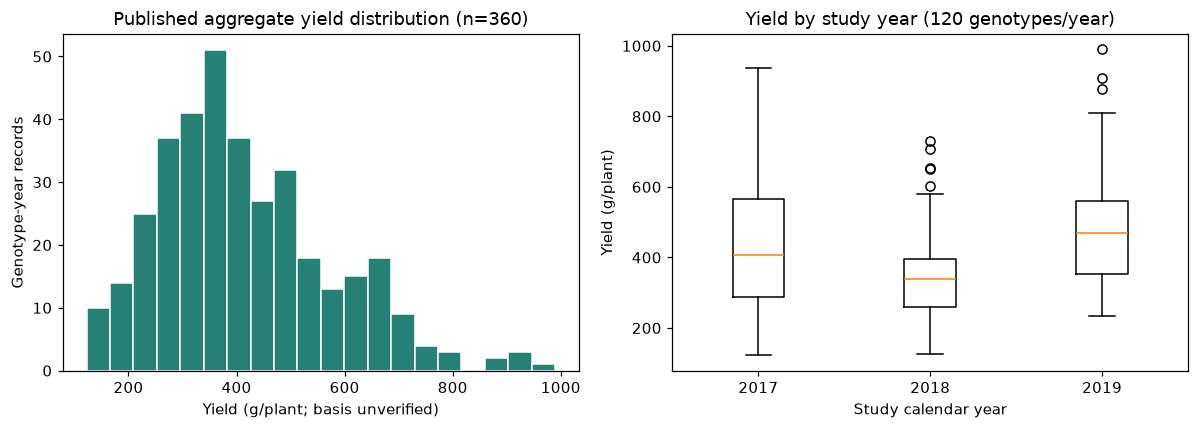

In [15]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].hist(clean[TARGET], bins=20, color='#268174', edgecolor='white')
axes[0].set(title='Published aggregate yield distribution (n=360)', xlabel='Yield (g/plant; basis unverified)', ylabel='Genotype-year records')
axes[1].boxplot([clean.loc[clean.study_calendar_year==year,TARGET] for year in sorted(clean.study_calendar_year.unique())],
                tick_labels=sorted(clean.study_calendar_year.unique()))
axes[1].set(title='Yield by study year (120 genotypes/year)', xlabel='Study calendar year', ylabel='Yield (g/plant)')
figure_done(fig)

Yield ranges from 122.4 to 989.6 g/plant, with mean 416.44 and median 385.83 g/plant.
The upper tail makes large errors relevant to RMSE. The year plot describes repeated genotype aggregates,
not independent plant replicates or a time-series forecasting experiment.

,count,mean,std,min,25%,50%,75%,max
Selected predictor,,,,,,,,
plant_height_cm,360.0,60.298917,7.738708,37.910000,55.500000,60.816667,65.683333,79.366667
main_branches,360.0,4.123148,0.866135,2.000000,3.333333,4.000000,4.666667,6.000000
leaf_length_cm,360.0,8.671572,1.400723,5.166667,7.666667,8.666667,9.541667,13.233333
leaf_breadth_cm,360.0,5.002960,1.474704,2.500000,4.100000,4.900000,5.766667,22.700000
days_to_50pct_flowering,360.0,73.799074,6.349956,59.000000,69.333333,74.000000,77.666667,99.333333


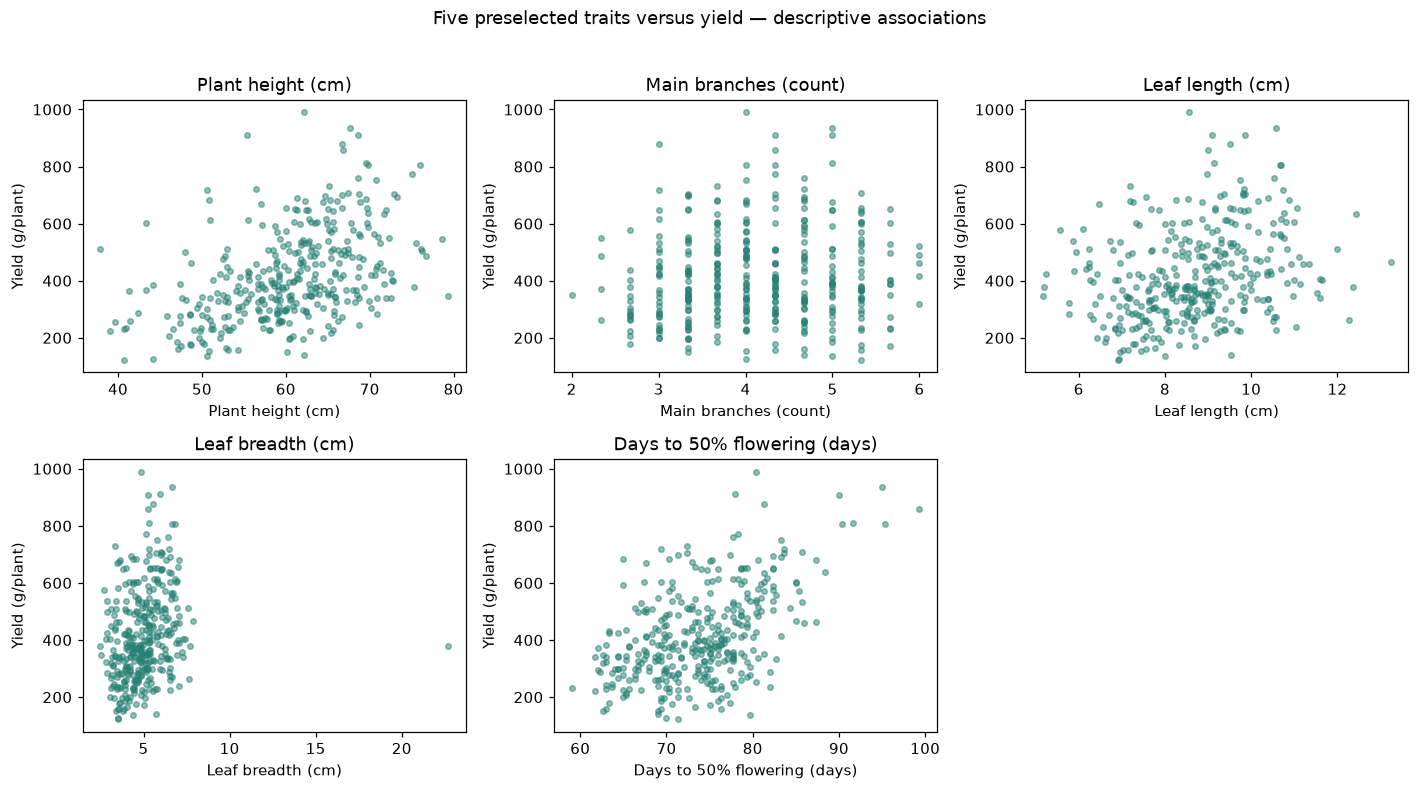

In [16]:
labels = {'plant_height_cm':'Plant height (cm)', 'main_branches':'Main branches (count)',
          'leaf_length_cm':'Leaf length (cm)', 'leaf_breadth_cm':'Leaf breadth (cm)',
          'days_to_50pct_flowering':'Days to 50% flowering (days)', TARGET:'Yield (g/plant)'}
show(clean[FEATURES].describe().T.rename_axis('Selected predictor'))
fig, axes = plt.subplots(2,3,figsize=(13,7))
for ax, feature in zip(axes.flat, FEATURES):
    ax.scatter(clean[feature],clean[TARGET],s=13,alpha=.5,color='#268174')
    ax.set(xlabel=labels[feature], ylabel='Yield (g/plant)',title=labels[feature])
axes.flat[-1].axis('off')
fig.suptitle('Five preselected traits versus yield — descriptive associations',y=1.02)
figure_done(fig)

,plant_height_cm,main_branches,leaf_length_cm,leaf_breadth_cm,days_to_50pct_flowering,fruit_yield_g_per_plant
plant_height_cm,1.000,-0.204,0.305,0.249,0.349,0.454
main_branches,-0.204,1.000,0.060,-0.001,0.041,0.094
leaf_length_cm,0.305,0.060,1.000,0.753,0.331,0.284
leaf_breadth_cm,0.249,-0.001,0.753,1.000,0.256,0.231
days_to_50pct_flowering,0.349,0.041,0.331,0.256,1.000,0.502
fruit_yield_g_per_plant,0.454,0.094,0.284,0.231,0.502,1.000


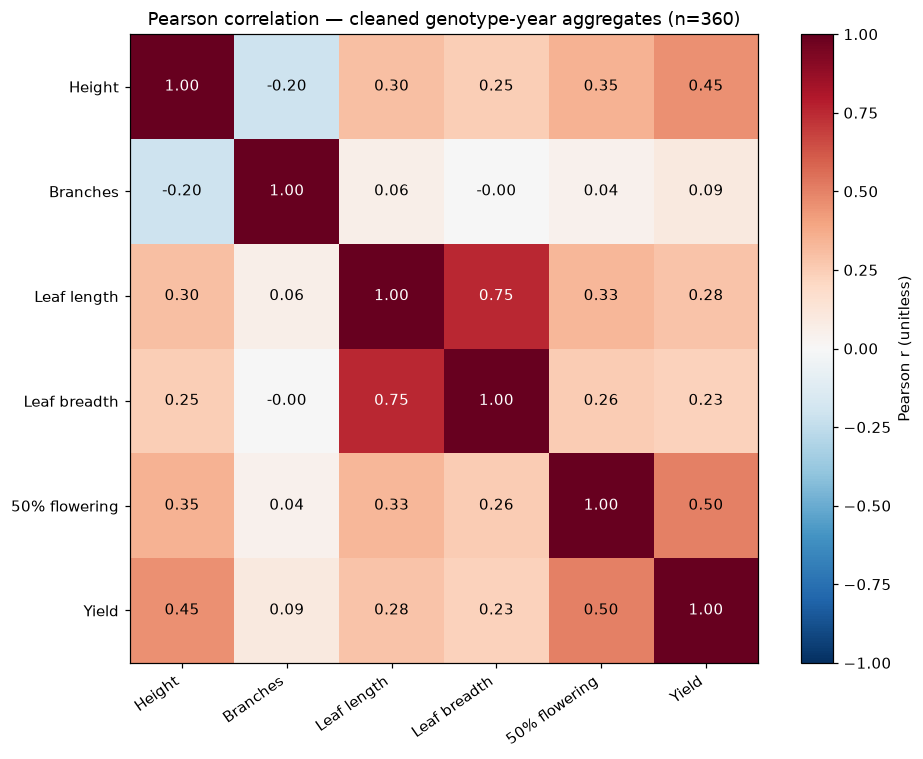

In [17]:
correlation = clean[FEATURES+[TARGET]].corr(method='pearson')
show(correlation.round(3))
fig, ax = plt.subplots(figsize=(9,7))
image = ax.imshow(correlation,vmin=-1,vmax=1,cmap='RdBu_r')
short_labels = ['Height','Branches','Leaf length','Leaf breadth','50% flowering','Yield']
ax.set_xticks(range(6),short_labels,rotation=35,ha='right')
ax.set_yticks(range(6),short_labels)
for i in range(6):
    for j in range(6):
        ax.text(j,i,f'{correlation.iloc[i,j]:.2f}',ha='center',va='center',
                color='white' if abs(correlation.iloc[i,j])>.65 else 'black')
ax.set_title('Pearson correlation — cleaned genotype-year aggregates (n=360)')
fig.colorbar(image,ax=ax,label='Pearson r (unitless)')
figure_done(fig)

Flowering time (r≈0.502) and height (r≈0.454) have the strongest positive linear associations with yield
among the selected predictors. Branch count has a weak linear association (r≈0.094).
These are pooled, descriptive correlations with repeated genotypes and possible confounding.
They neither establish causality nor provide a basis for changing the frozen feature set after seeing test data.
A weak linear correlation does not exclude a nonlinear model contribution.

## C. Actual preprocessing and feature selection
`preprocessing.py` validates required columns, genotype-year uniqueness, species and observation type;
coerces five predictors and target to numeric; drops missing targets; rejects negative yields; sorts by
genotype and study-year index. It preserves source metadata. There is no recorded normalization,
outlier deletion, feature selection search, or imputation in that script.
Median imputation is inside each training pipeline, fitted on the training fold only.
Only SVR additionally uses a training-fitted StandardScaler. Tree models are not scaled.
The following reconstructs the transformations **in memory** and checks the saved output.

In [18]:
reconstructed = raw.copy()
for col in FEATURES+[TARGET]:
    reconstructed[col] = pd.to_numeric(reconstructed[col],errors='coerce')
removed_targets = int(reconstructed[TARGET].isna().sum())
reconstructed = reconstructed.dropna(subset=[TARGET]).sort_values(['genotype_id','study_year_index']).reset_index(drop=True)
assert reconstructed.species.eq('Capsicum chinense').all()
assert reconstructed.observation_unit.eq('genotype_year_trait_aggregate').all()
assert reconstructed[TARGET].ge(0).all()
pd.testing.assert_frame_equal(reconstructed,clean,check_exact=False,rtol=1e-12,atol=1e-12)
print(f'Original: {len(raw)}; targets removed: {removed_targets}; cleaned: {len(clean)}')
show(pd.DataFrame({'selected_predictor': FEATURES, 'meaning_and_unit':[labels[f] for f in FEATURES]}))
excluded = [c for c in clean.columns if c not in FEATURES+[TARGET]]
show(pd.DataFrame({'excluded_column': excluded}))

Original: 360; targets removed: 0; cleaned: 360


,selected_predictor,meaning_and_unit
0,plant_height_cm,Plant height (cm)
1,main_branches,Main branches (count)
2,leaf_length_cm,Leaf length (cm)
3,leaf_breadth_cm,Leaf breadth (cm)
4,days_to_50pct_flowering,Days to 50% flowering (days)


,excluded_column
0,source_doi
1,source_country
2,study_site
3,species
4,genotype_id
5,study_year_index
6,study_calendar_year
7,observation_unit
8,replicates_pooled_in_published_record
9,fruit_yield_weight_basis


The five traits are a fixed, interpretable prototype input set. No ablation study proving optimality is present.
Height, branching and leaf dimensions describe plant structure; days to 50% flowering captures a phenological
summary, but does not make this a dynamic growth-stage-aware system. Its availability also limits how early
an estimate can be made.

Genotype, year and source metadata are retained for audit/grouping, not used as model inputs. Species and
site are constant in this dataset. Fruit count, fruit dimensions, maturity and capsaicin are excluded:
some may only be available late or at harvest, and fruit count is closely tied to the target. Their inclusion
could introduce timing/availability leakage in an earlier prediction use case. This is a precautionary
rationale, not evidence that every excluded variable is inherently leakage. Yield itself must never be an input.

## D. Dataset splitting and cross-validation
The existing split uses `GroupShuffleSplit(test_size=0.15, random_state=42)` on genotype ID.
All three records for a genotype stay together. The saved development set contains five GroupKFold
validation assignments; test fold is -1. Validation supports comparison and tuning within development;
the held-out set evaluates frozen settings afterwards. This split tests unseen genotypes in the same study
context, not unseen countries, farms or future years. The code below recreates indices only; it writes nothing.

In [19]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
assert (len(dev),len(test),dev.genotype_id.nunique(),test.genotype_id.nunique()) == (306,54,102,18)
assert set(dev.genotype_id).isdisjoint(test.genotype_id)
assert test.cv_fold.eq(-1).all()
assert dev.groupby('genotype_id').cv_fold.nunique().eq(1).all()
assert set(dev.cv_fold)=={1,2,3,4,5}
key = ['genotype_id','study_year_index']
combined = pd.concat([dev.drop(columns='cv_fold'),test.drop(columns='cv_fold')]).sort_values(key).reset_index(drop=True)
pd.testing.assert_frame_equal(combined,clean,check_exact=False,rtol=1e-12,atol=1e-12)
di,ti = next(GroupShuffleSplit(n_splits=1,test_size=.15,random_state=42).split(clean,groups=clean.genotype_id))
for expected, saved in [(clean.iloc[di],dev),(clean.iloc[ti],test)]:
    pd.testing.assert_frame_equal(expected.reset_index(drop=True),saved.drop(columns='cv_fold'),check_exact=False,rtol=1e-12,atol=1e-12)
fold_rows=[]
for fold,(train_i,val_i) in enumerate(GroupKFold(n_splits=5).split(dev,groups=dev.genotype_id),1):
    train,valid=dev.iloc[train_i],dev.iloc[val_i]
    assert set(train.genotype_id).isdisjoint(valid.genotype_id)
    assert valid.cv_fold.eq(fold).all()
    fold_rows.append({'fold':fold,'training_rows':len(train),'validation_rows':len(valid),
                      'training_genotypes':train.genotype_id.nunique(),'validation_genotypes':valid.genotype_id.nunique(),'genotype_overlap':0})
show(pd.DataFrame(fold_rows))
print('Development/test genotype overlap: 0; reconstructed split and fold assignments match saved files.')

,fold,training_rows,validation_rows,training_genotypes,validation_genotypes,genotype_overlap
0,1,243,63,81,21,0
1,2,243,63,81,21,0
2,3,246,60,82,20,0
3,4,246,60,82,20,0
4,5,246,60,82,20,0


Development/test genotype overlap: 0; reconstructed split and fold assignments match saved files.


## E. Existing model benchmarks
The original XGBoost, Random Forest and SVR are learned regressors. Training Mean predicts only the
training-target average and is a simple reference. Original settings are defined in `training.create_models`:
XGBoost: 200 trees, depth 3, learning rate .05, subsample/column subsample .8;
Random Forest: 200 trees, depth 6, minimum leaf size 2; RBF SVR: C=10, epsilon=.1.
All pipelines use median imputation; SVR adds scaling. Random state is 42 where applicable.
Saved CV means are unweighted means of five fold metrics, with sample standard deviations;
pooled out-of-fold scores need not equal these means. Error bars show fold variation, not confidence intervals.

,MAE mean (g/plant),MAE_std,RMSE mean (g/plant),RMSE_std,R2_mean,R2_std
model,,,,,,
Random Forest,94.932,9.923,120.792,12.346,0.373,0.202
XGBoost,97.468,9.236,125.007,11.639,0.329,0.212
SVR,106.261,5.261,136.240,10.666,0.233,0.072
Training Mean,127.434,9.746,158.148,14.206,-0.028,0.029


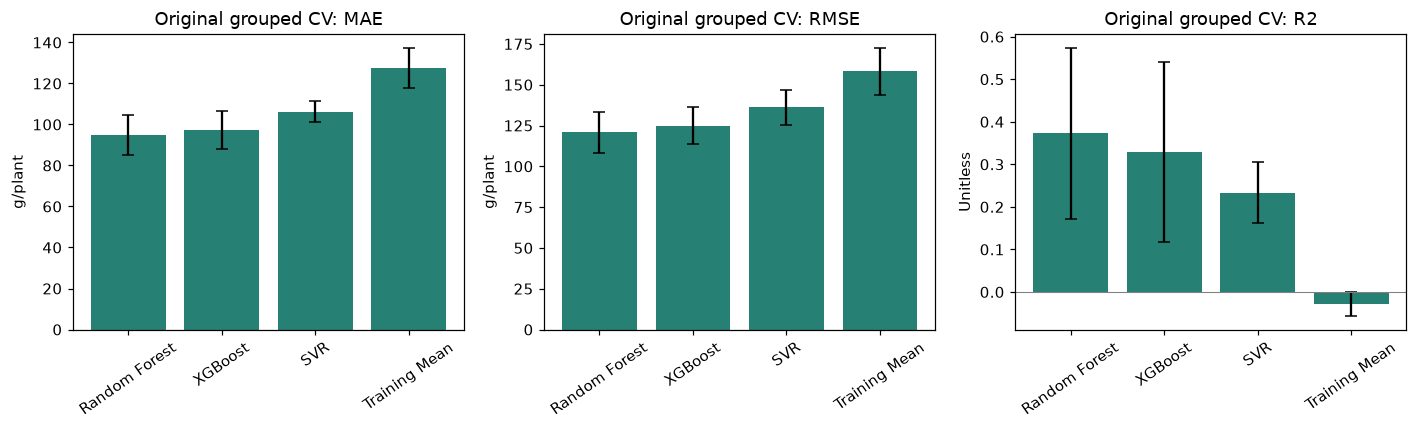

In [20]:
cv = pd.read_csv(EXP/'yield_cv_summary.csv').set_index('model')
fold_metrics = pd.read_csv(EXP/'yield_cv_fold_metrics.csv')
cv_predictions = pd.read_csv(EXP/'yield_cv_predictions.csv')
assert len(fold_metrics)==20 and len(cv_predictions)==4*306
for row in fold_metrics.itertuples():
    subset=cv_predictions[(cv_predictions.model==row.model)&(cv_predictions.fold==row.fold)]
    assert len(subset)==row.validation_rows
    expected_dev=dev.loc[dev.cv_fold==row.fold,['genotype_id',TARGET]].rename(columns={TARGET:'actual_yield_g'})
    pd.testing.assert_frame_equal(subset[['genotype_id','actual_yield_g']].reset_index(drop=True),expected_dev.reset_index(drop=True),check_exact=False,rtol=1e-12,atol=1e-12)
    recalculated=calculate_metrics(subset.actual_yield_g,subset.predicted_yield_g)
    for metric,value in recalculated.items():
        assert np.isclose(value,getattr(row,metric),rtol=1e-10)
    if row.model=='Training Mean':
        assert np.allclose(subset.predicted_yield_g,dev.loc[dev.cv_fold!=row.fold,TARGET].mean())
recomputed=fold_metrics.groupby('model')[['MAE','RMSE','R2']].agg(['mean','std'])
recomputed.columns=[f'{m}_{s}' for m,s in recomputed.columns]
pd.testing.assert_frame_equal(cv.sort_index(),recomputed.sort_index(),check_exact=False,rtol=1e-10,atol=1e-10)
show(cv.round(3).rename(columns={'MAE_mean':'MAE mean (g/plant)','RMSE_mean':'RMSE mean (g/plant)'}))
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,metric in zip(axes,['MAE','RMSE','R2']):
    ax.bar(cv.index,cv[f'{metric}_mean'],yerr=cv[f'{metric}_std'],capsize=4,color='#268174')
    ax.axhline(0,color='gray',linewidth=.7)
    ax.set(title=f'Original grouped CV: {metric}',ylabel='Unitless' if metric=='R2' else 'g/plant')
    ax.tick_params(axis='x',rotation=35)
figure_done(fig)

Random Forest has the lowest **original** CV MAE (94.932 g/plant), followed by XGBoost (97.468),
SVR (106.261), and Training Mean (127.434). Learned models improve on the simple reference here,
but fold variation and limited data prevent claims of strong field accuracy.

## F. Existing XGBoost hyperparameter tuning
`tune_xgboost.py` searched 12 candidates using RandomizedSearchCV, negative MAE, random state 42,
and PredefinedSplit reusing the same five genotype-grouped folds. The selected estimator was refitted
on 306 development records. Tuning did not use held-out records in the implementation.
The saved search contains MAE only: tuned CV RMSE and R² are not available and are not invented.
Metadata `test_evaluated: false` records the training/tuning stage, not the absence of later final-test CSVs.

,parameter,selected_value
0,model__subsample,1.0
1,model__reg_lambda,5.0
2,model__n_estimators,100.0
3,model__min_child_weight,1.0
4,model__max_depth,2.0
5,model__learning_rate,0.1
6,model__colsample_bytree,1.0


,rank_test_score,Negative CV MAE (g/plant),std_test_score,params
11,1,-92.901196,8.773855,"{'model__subsample': 1.0, 'model__reg_lambda':..."
10,2,-93.918166,7.004156,"{'model__subsample': 0.8, 'model__reg_lambda':..."
2,3,-94.789311,6.331940,"{'model__subsample': 1.0, 'model__reg_lambda':..."
1,4,-95.272285,5.484566,"{'model__subsample': 0.8, 'model__reg_lambda':..."
4,5,-95.734711,7.733683,"{'model__subsample': 0.8, 'model__reg_lambda':..."
0,6,-96.470884,9.700357,"{'model__subsample': 1.0, 'model__reg_lambda':..."
7,7,-97.043742,7.498551,"{'model__subsample': 0.8, 'model__reg_lambda':..."
6,8,-98.094827,10.135083,"{'model__subsample': 1.0, 'model__reg_lambda':..."
5,9,-98.245751,4.254974,"{'model__subsample': 1.0, 'model__reg_lambda':..."
9,10,-98.802856,11.313372,"{'model__subsample': 1.0, 'model__reg_lambda':..."


,experiment,CV MAE (g/plant)
0,Original XGBoost,97.468
1,Tuning-selected XGBoost,92.901


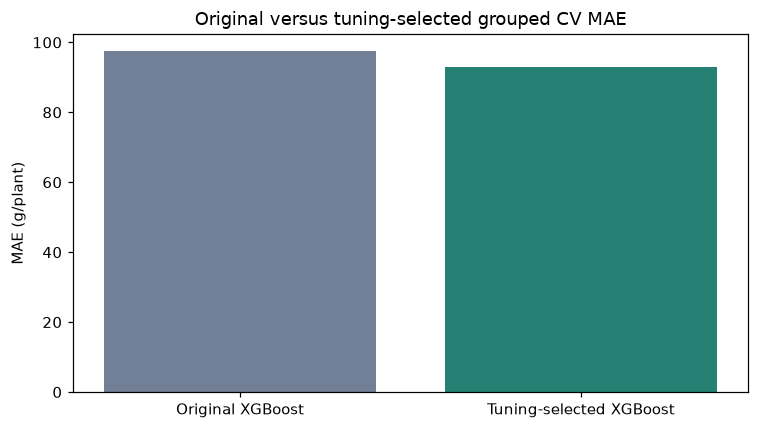

In [21]:
import ast
search = pd.read_csv(EXP/'xgboost_tuning_results.csv')
tuning_meta = json.loads((MODELS/'xgboost_tuning_metadata.json').read_text())
model_meta = json.loads((MODELS/'yield_model_metadata.json').read_text())
assert model_meta['features']==tuning_meta['features']==FEATURES
best = search.sort_values(['rank_test_score','mean_test_score'],ascending=[True,False]).iloc[0]
assert len(search)==12
assert np.isclose(-best.mean_test_score,tuning_meta['best_cv_mae'])
assert ast.literal_eval(best.params)==tuning_meta['best_parameters']
fold_score_cols=[f'split{i}_test_score' for i in range(5)]
assert np.allclose(search[fold_score_cols].mean(axis=1),search.mean_test_score)
assert np.allclose(search[fold_score_cols].std(axis=1,ddof=0),search.std_test_score)
show(pd.DataFrame({'parameter': list(tuning_meta['best_parameters']), 'selected_value':list(tuning_meta['best_parameters'].values())}))
show(search[['rank_test_score','mean_test_score','std_test_score','params']].sort_values('rank_test_score').rename(columns={'mean_test_score':'Negative CV MAE (g/plant)'}))
comparison=pd.DataFrame({'experiment':['Original XGBoost','Tuning-selected XGBoost'],
                        'CV MAE (g/plant)':[cv.loc['XGBoost','MAE_mean'],tuning_meta['best_cv_mae']]})
show(comparison.round(3))
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(comparison.experiment,comparison['CV MAE (g/plant)'],color=['#718096','#268174'])
ax.set(title='Original versus tuning-selected grouped CV MAE',ylabel='MAE (g/plant)')
figure_done(fig)

Selected settings: 100 trees, depth 2, learning rate .1, minimum child weight 1,
subsample 1, column subsample 1, L2 regularization 5. CV MAE falls from 97.468 to 92.901 g/plant.
Because the same validation folds chose the settings and supplied the reported score, that improvement
may be optimistic. This is not nested CV and is not independent evidence of generalization.

## G. Final held-out evaluation — frozen saved outputs
`evaluation.py` loads tuned XGBoost and fits the already configured learned baselines/reference using
only development data before predicting the 54 held-out rows (18 genotypes).
**Do not run that entry point here:** it refits baselines and overwrites experiment files.
We recalculate metrics from saved predictions only and check them against the metric CSV.
The prediction CSV lacks study-year identifiers. Row order and genotype/actual-value comparisons below
check consistency with the test CSV; a genotype-only merge would be ambiguous across three years.

,MAE (g/plant),RMSE (g/plant),R2
model,,,
Tuned XGBoost,120.274,167.548,0.096
Random Forest,114.499,158.717,0.189
SVR,109.857,155.793,0.218
Training Mean,137.070,176.594,-0.004


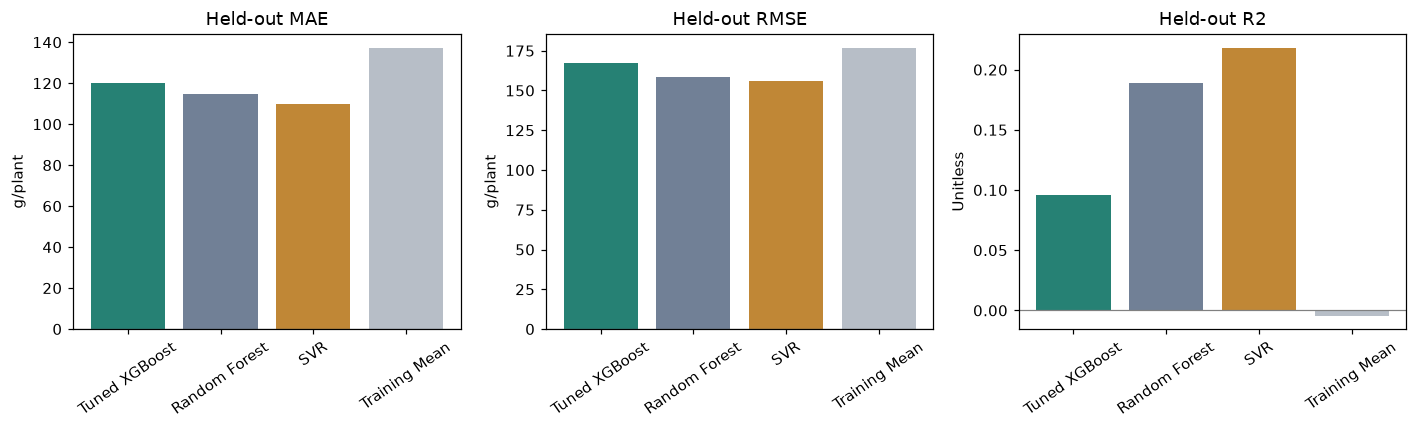

In [22]:
final = pd.read_csv(EXP/'yield_final_test_metrics.csv').set_index('model')
predictions = pd.read_csv(EXP/'yield_final_test_predictions.csv')
assert set(final.index)==set(predictions.model)=={'Tuned XGBoost','Random Forest','SVR','Training Mean'}
verified=[]
for name in final.index:
    subset=predictions.loc[predictions.model==name].reset_index(drop=True)
    assert len(subset)==54
    assert subset.genotype_id.tolist()==test.genotype_id.tolist()
    assert np.allclose(subset.actual_yield_g,test[TARGET],rtol=1e-12)
    assert np.isfinite(subset[['actual_yield_g','predicted_yield_g']]).all().all()
    scores=calculate_metrics(subset.actual_yield_g,subset.predicted_yield_g)
    for key,column in [('MAE','MAE_g_per_plant'),('RMSE','RMSE_g_per_plant'),('R2','R2')]:
        assert np.isclose(scores[key],final.loc[name,column],rtol=1e-10)
    if name=='Training Mean':
        assert np.allclose(subset.predicted_yield_g,dev[TARGET].mean())
    verified.append({'model':name,**scores})
show(pd.DataFrame(verified).set_index('model').round(3).rename(columns={'MAE':'MAE (g/plant)','RMSE':'RMSE (g/plant)'}))
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,column in zip(axes,['MAE_g_per_plant','RMSE_g_per_plant','R2']):
    ax.bar(final.index,final[column],color=['#268174','#718096','#c08736','#b7bec7'])
    ax.axhline(0,color='gray',linewidth=.8)
    ax.set(title='Held-out '+column.split('_')[0],ylabel='Unitless' if column=='R2' else 'g/plant')
    ax.tick_params(axis='x',rotation=35)
figure_done(fig)

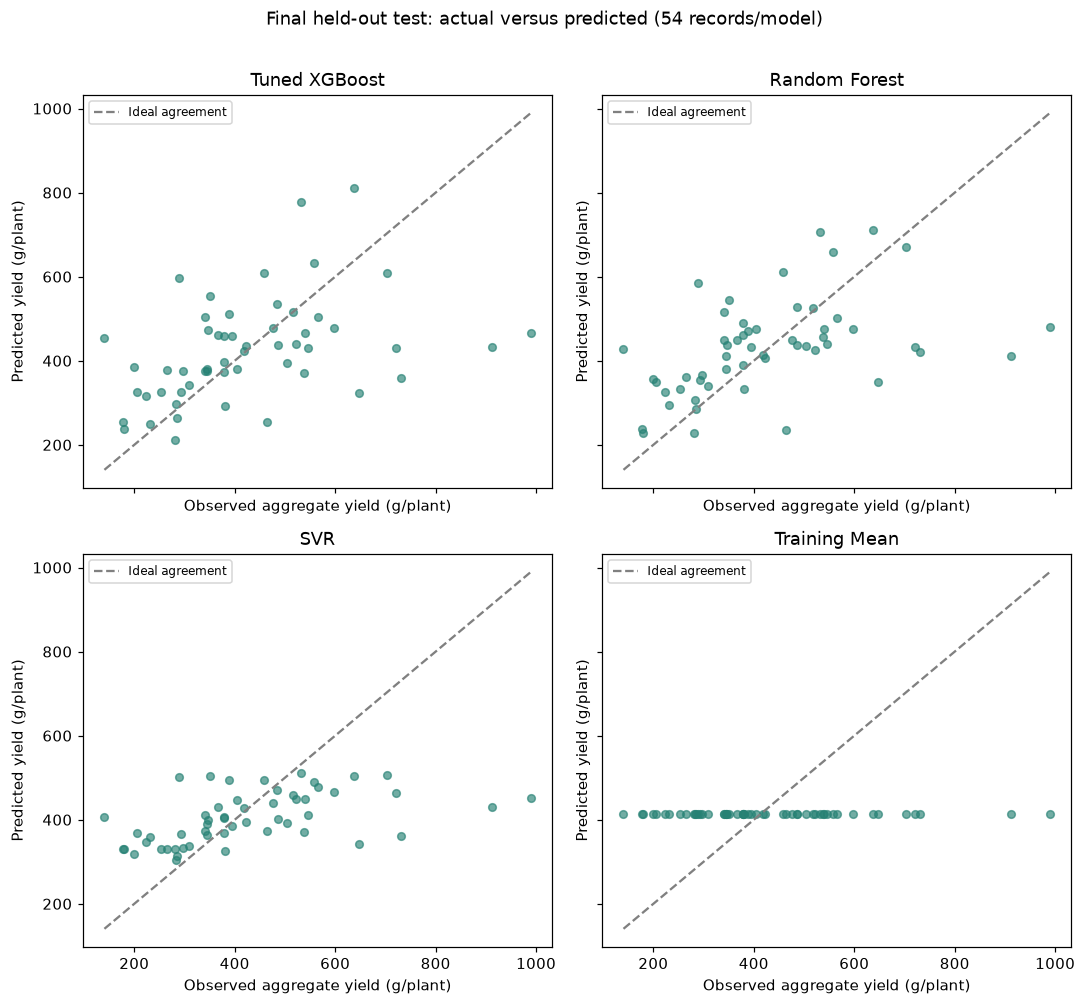

In [23]:
fig,axes=plt.subplots(2,2,figsize=(10,9),sharex=True,sharey=True)
low=min(predictions.actual_yield_g.min(),predictions.predicted_yield_g.min())
high=max(predictions.actual_yield_g.max(),predictions.predicted_yield_g.max())
for ax,name in zip(axes.flat,final.index):
    subset=predictions[predictions.model==name]
    ax.scatter(subset.actual_yield_g,subset.predicted_yield_g,alpha=.65,s=25,color='#268174')
    ax.plot([low,high],[low,high],'--',color='gray',label='Ideal agreement')
    ax.set(title=name,xlabel='Observed aggregate yield (g/plant)',ylabel='Predicted yield (g/plant)')
    ax.legend(fontsize=8)
fig.suptitle('Final held-out test: actual versus predicted (54 records/model)',y=1.01)
figure_done(fig)

,count,Mean residual (g/plant),Residual SD (g/plant),min,max
model,,,,,
Random Forest,54,-4.749,160.135,-296.622,510.320
SVR,54,21.633,155.732,-265.038,538.928
Training Mean,54,11.607,177.866,-274.113,574.904
Tuned XGBoost,54,1.261,169.116,-312.781,524.497


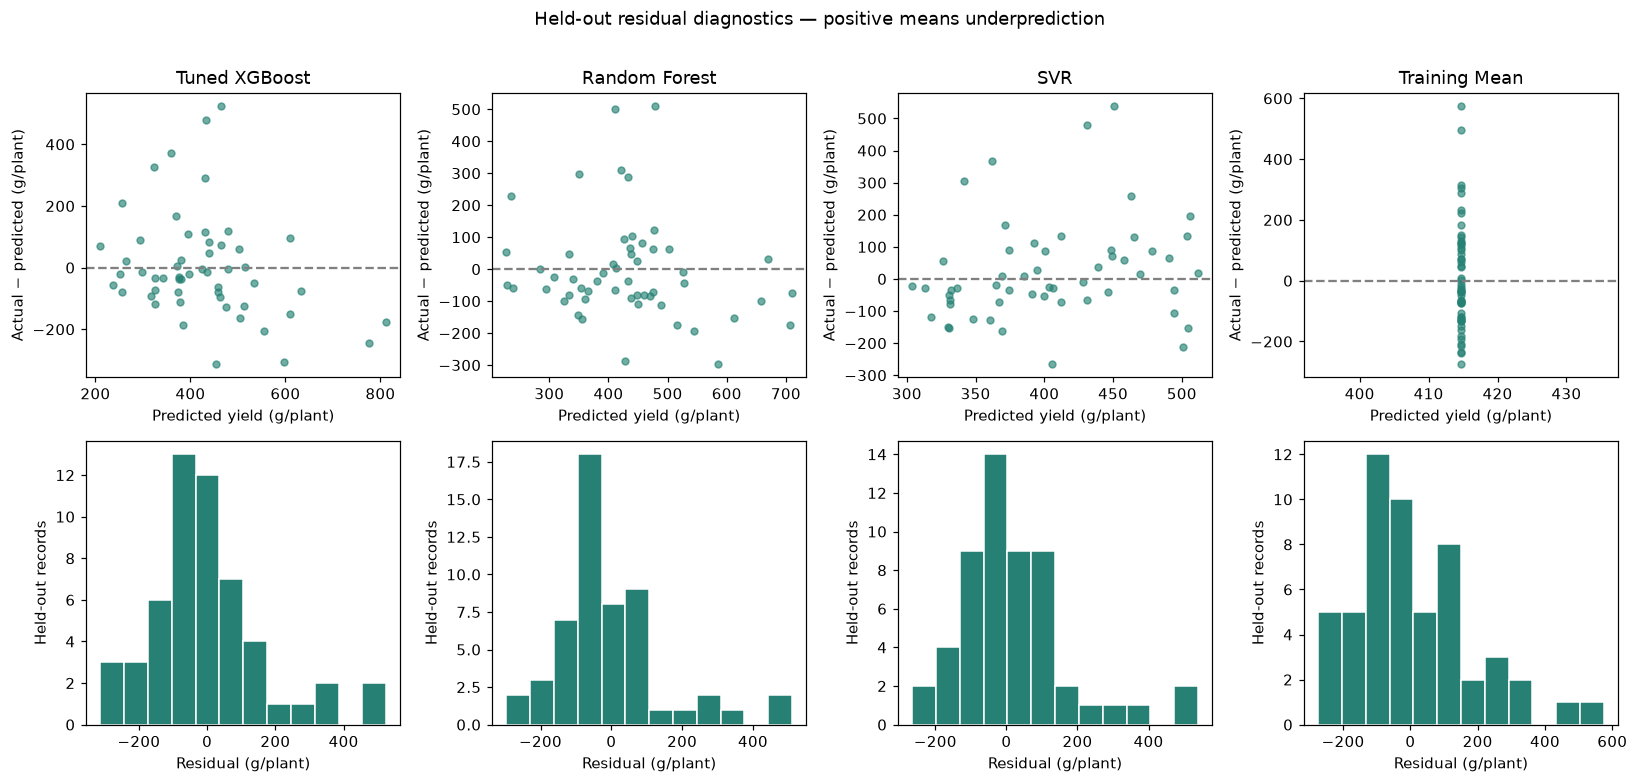

Tuned XGBoost residual/predicted correlation: -0.291


In [24]:
residuals=predictions.assign(residual_g=predictions.actual_yield_g-predictions.predicted_yield_g)
show(residuals.groupby('model').residual_g.agg(['count','mean','std','min','max']).round(3).rename(columns={'mean':'Mean residual (g/plant)','std':'Residual SD (g/plant)'}))
fig,axes=plt.subplots(2,4,figsize=(15,7))
for j,name in enumerate(final.index):
    subset=residuals[residuals.model==name]
    axes[0,j].scatter(subset.predicted_yield_g,subset.residual_g,alpha=.65,s=20,color='#268174')
    axes[0,j].axhline(0,color='gray',linestyle='--')
    axes[0,j].set(title=name,xlabel='Predicted yield (g/plant)',ylabel='Actual − predicted (g/plant)')
    axes[1,j].hist(subset.residual_g,bins=12,color='#268174',edgecolor='white')
    axes[1,j].set(xlabel='Residual (g/plant)',ylabel='Held-out records')
fig.suptitle('Held-out residual diagnostics — positive means underprediction',y=1.01)
figure_done(fig)
print('Tuned XGBoost residual/predicted correlation:',round(residuals.loc[residuals.model=='Tuned XGBoost',['residual_g','predicted_yield_g']].corr().iloc[0,1],3))

SVR has the lowest observed test MAE/RMSE and highest R². Tuned XGBoost's R²≈0.096 indicates
limited predictive performance on this holdout. Training Mean's slightly negative R² means greater
squared error than predicting the **test-set mean**; its actual predictions use the development mean.
R² is not percentage accuracy. RMSE exceeding MAE indicates sensitivity to larger misses.
The agreement plots show the difficulty of reproducing high observed yields with this feature set;
residual plots describe error patterns, not calibrated uncertainty or independent hypothesis tests.
Only 18 independent genotype groups are held out, so rankings may be unstable.
Why SVR ranked first is not established by these CSVs: smooth RBF behavior, regularization and sampling
variation are hypotheses. These observations must not be used to tune again or replace the frozen API
model using this same test set. Future selection needs development-only/nested validation and a new test.

## H. Explainable AI — existing tuned XGBoost explanations
`explainability.py` uses the fitted median imputer, TreeExplainer, and 306 development records.
Mean absolute SHAP describes average contribution magnitude in model-output units (g/plant), not direction,
causal importance, or predictive accuracy. Correlated inputs may share attribution.

,feature,Mean absolute SHAP (g/plant),rank
0,plant_height_cm,53.157,1
1,days_to_50pct_flowering,36.620,2
2,leaf_breadth_cm,22.375,3
3,main_branches,16.988,4
4,leaf_length_cm,14.523,5


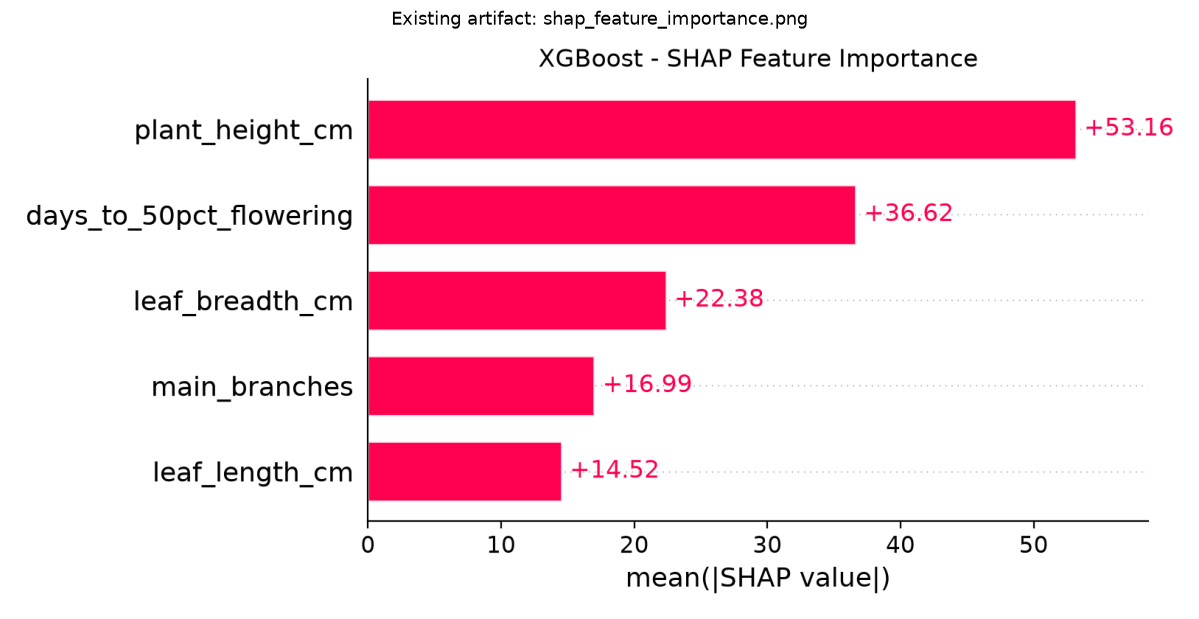

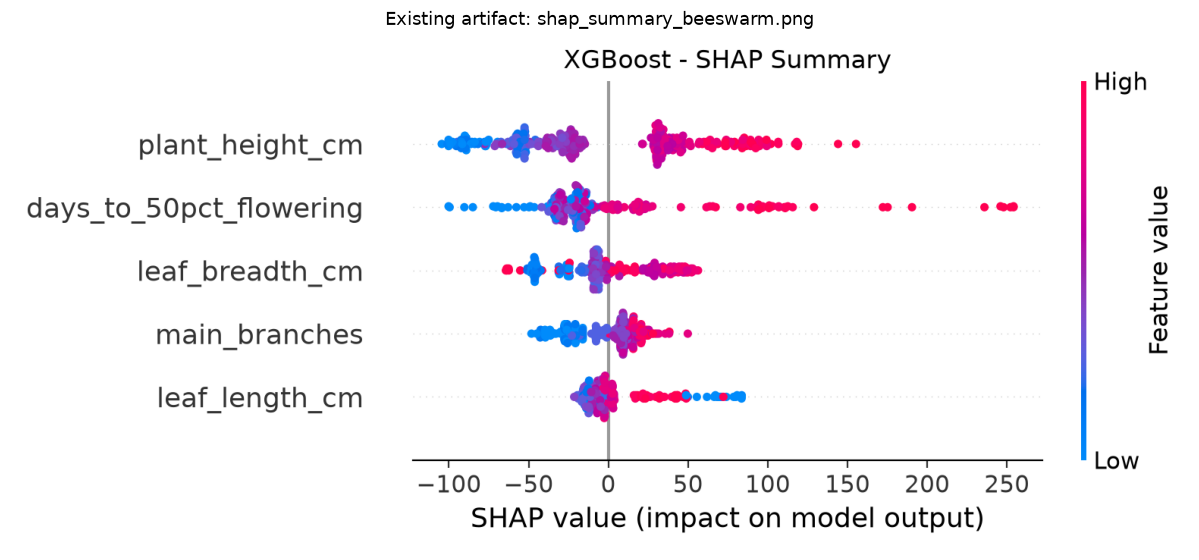

Optional saved model availability (not loaded or changed):
xgboost_yield_development.joblib True
xgboost_tuned_development.joblib True


In [25]:
importance=pd.read_csv(EXP/'shap_feature_importance.csv')
assert set(importance.feature)==set(FEATURES) and len(importance)==5
assert importance.mean_absolute_shap.ge(0).all()
show(importance.assign(rank=np.arange(1,len(importance)+1)).rename(columns={'mean_absolute_shap':'Mean absolute SHAP (g/plant)'}).round(3))
from PIL import Image
for filename in ['shap_feature_importance.png','shap_summary_beeswarm.png']:
    path=EXP/filename
    if path.is_file():
        with Image.open(path) as image:
            image.verify()
        pixels=plt.imread(path)
        fig,ax=plt.subplots(figsize=(11,7))
        ax.imshow(pixels)
        ax.axis('off')
        ax.set_title('Existing artifact: '+filename)
        figure_done(fig)
    else:
        print('Optional SHAP plot unavailable:',filename,'— numeric CSV analysis remains available.')
print('Optional saved model availability (not loaded or changed):')
for name in ['xgboost_yield_development.joblib','xgboost_tuned_development.joblib']:
    print(name, (MODELS/name).is_file())

Height ranks first (53.157 g/plant mean absolute SHAP), followed by flowering time (36.620),
leaf breadth (22.375), branches (16.988), and leaf length (14.523).
The existing beeswarm shows signed model contributions and feature-value coloring across development
observations; the global CSV alone cannot show a trait's direction of effect.
A local explanation would decompose a **particular** prediction relative to an explainer baseline.
Neither the current API nor frontend returns per-request SHAP values: the UI shows global static importance.
SHAP does not prove causality or establish that changing height will cause a yield increase.
No SHAP recomputation or saved-model deserialization is needed for this notebook.

## I. Research findings, limitations and next work
- Verified artifacts contain 360 genotype-year aggregates, not 360 independent plants or sensor sequences.
  The 120 genotypes each contribute three years; published records already pool replicates.
- The split and folds prevent genotype overlap; fold-local preprocessing prevents preprocessing leakage.
  They do not establish chronological, regional, farm-level or cultivar-population transfer.
- Original CV favored Random Forest. Tuning-selected XGBoost MAE is 92.901 g/plant, but selection optimism
  remains. Test MAE is 120.274 for tuned XGBoost versus 109.857 for SVR and 137.070 for Training Mean.
  This is preliminary, limited performance, not high predictive accuracy.
- Fresh/dry yield basis is unverified. Indian aggregate records cannot validate Sri Lankan individual-plant
  fresh yield, next-seven-day harvest quantity or any specific future harvest date.
- Weather, calibrated live C1 sensing, temporal growth-stage modeling and C3/C4 integration are future work.
- Acquire consented local longitudinal records with plant/plot/genotype identifiers; timestamps and growth stage;
  calibrated weather/soil measurements; harvest date, measured fresh mass and cumulative versus interval yield;
  management and replicate information. Verify source labels and units before defining the forecasting target.
- Agree C1 data contracts and input-availability cutoffs, collect across farms/seasons, use farm/genotype/time
  splits appropriate to deployment, tune inside development (prefer nested grouped CV), freeze a model and
  evaluate on a new untouched external test. Assess uncertainty and calibration using independent evidence.
- Supplement provenance reconstruction, model version/environment recording, and individual SHAP explanations
  remain work items. Existing joblib files contain fitted pipelines; metadata JSON is descriptive, not a model.

### Evidence integrity check
This final cell confirms the original local evidence files stayed unchanged during execution.
The notebook and its captured outputs are the only artifacts updated by the separate execution harness.

In [26]:
after_hashes={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in evidence_paths}
assert before_hashes==after_hashes, 'Original evidence changed during notebook execution.'
print(f'PASS: {len(before_hashes)} original evidence files unchanged; all dataset, split and metric assertions passed; any enabled training demonstration used in-memory estimators only.')
show(pd.DataFrame({'artifact':[str(p.relative_to(ROOT)) for p in evidence_paths], 'sha256':[after_hashes[p] for p in evidence_paths]}))

PASS: 28 original evidence files unchanged; all dataset, split and metric assertions passed; any enabled training demonstration used in-memory estimators only.


,artifact,sha256
0,backend\app\c2\yield_prediction\evaluation.py,dd4de29d33c91855f0bd23f6d9fef6afa22d7a259fb40f...
1,backend\app\c2\yield_prediction\explainability.py,26abd604492cd21d5f9809ab83232f86430b416e62c235...
2,backend\app\c2\yield_prediction\preprocessing.py,158b89ecf9e56e5fd20facad6bd0e157a91a7fdb694019...
3,backend\app\c2\yield_prediction\routes.py,c5c74eae20f84faf0cc8e7acdec0ba0463c858fedb547b...
4,backend\app\c2\yield_prediction\split_data.py,4d9895bf437b207231ca5b0f32c6c31cda828924cc0ac5...
5,backend\app\c2\yield_prediction\training.py,dabaaa6310a7f3afb781dacd20058f49649f7eeeb7cd9b...
6,backend\app\c2\yield_prediction\tune_xgboost.py,a9bc5523d3a53e4e0eb68bd0c30b1138e882ac5700546e...
7,backend\app\c2\yield_prediction\visualization.py,5effa5e277efbfcc3cf1e489933d16205e1754320c3544...
8,backend\data\c2\yield\processed\peerj_developm...,c03c347d90bc5c01f2a6c7a6f216d486a8a2e2f91de0d2...
9,backend\data\c2\yield\processed\peerj_test.csv,8a0389b2de0e61c40eefd76cd99e959349ec297acffe1d...
